# SocialChoice-05 : Gibbard-Satterthwaite sans mystere - la manipulation comme temoin (Rust)

**Navigation** : [<< 04-Computational-Aggregation](ChoixSocial-04-Computational-Aggregation-SAT-Z3-Python.ipynb) | [Index](README.md) | [Version Python](ChoixSocial-05-Gibbard-Satterthwaite-Python.ipynb) | [Version C#](ChoixSocial-05-Gibbard-Satterthwaite-CSharp.ipynb) | [06-Mobius >>](ChoixSocial-06-Mobius-Aggregation-Pouvoir-Manipulation-Python.ipynb)

**Lien** : Voir aussi [la version Python](ChoixSocial-05-Gibbard-Satterthwaite-Python.ipynb) - jumeau de reference du present carnet : les sorties Rust sont calibrees sur ses sorties commitees (registre de conformite `scripts/notebook_tools/rust_conformance.d/choixsocial-05-gibbard-satterthwaite.yaml`).

## Le temoin d'exploitation

Une regle de vote est **manipulable** s'il existe un profil de preferences et un electeur qui peut soumettre un bulletin **insincere** obtenant un resultat qu'il prefere au resultat sincere. Gibbard (1973) et Satterthwaite (1975) ont prouve que pour **toute regle surjective et non dictatoriale** sur au moins 3 alternatives (preferences lineaires strictes), il **existe** un profil manipulable - le theoreme ne dit pas que tout profil l'est.

La consequence epistemologique est importante : le bulletin insincere est un **temoin** d'exploitation. Quand un electeur ment, il exhibe un bulletin et un vainqueur qui n'aurait pas existe avec un bulletin sincere - et la preuve d'exploitation est constructive. C'est le noyau mathematique propre de ce que Arrow designait comme l'impossibilite d'eviter la strategie sans tomber dans la dictature.

Trois parties, chacune composee d'un exemple guide resolu et d'un exercice a completer :
1. **Une election concrete** - 3 votants, 3 candidats, regle Pluralite. Exemple guide : le vainqueur sincere et sa sensibilite au tiebreak. Exercice : construire un profil a 4 votants ou le tiebreak decide.
2. **Le temoin** - identifier le bulletin insincere qui ameliore le sort d'un electeur. Exemple guide : exhiber le temoin (bulletin + vainqueur + gain). Exercice : generaliser la recherche a un nombre quelconque de votants.
3. **Comparer les regles** - Pluralite vs Borda : meme profil, meme temoin ? Exemple guide : mesurer le cout de la recherche de manipulation. Exercice : trouver un profil a 3 votants ou Borda est manipulable.

Le profil canonique est celui de Satterthwaite (1975), section 4 : 3 votants, preferences lineaires strictes, 3 alternatives. La manipulation existe mais elle est **fragile** (depend du tiebreak). C'est cette fragilite qui rend le theoreme contre-intuitif : on pourrait croire que la manipulation est rare. Elle est structurellement toujours presente.

**Portage Rust.** Le carnet est le jumeau Rust du carnet Python : memes cellules, memes sections, memes sorties attendues. Les candidats sont des `char` (le `{:?}` d'un `[char; 3]` rend `['A', 'B', 'C']`, exactement le `str(list)` de Python), la table des six bulletins remplace `itertools.permutations`, et les deux figures sont tracees avec `plotters` en SVG inline (sans ecriture de fichier).


## 1. Le modele : 3 votants, 3 candidats, regles usuelles

On considere un corps electoral de 3 votants qui doivent choisir parmi 3 alternatives `A, B, C`. Chaque votant `i` a des preferences lineaires strictes (un ordre total sans ex-aequo) sur les alternatives.

**Regles de vote** :
- **Pluralite** : chaque electeur vote pour son candidat prefere. Le candidat avec le plus de voix gagne. En cas d'egalite, on applique un tiebreak lexicographique (`A > B > C`).
- **Borda** : chaque electeur etablit un classement. Le candidat au rang 1 recoit 2 points, rang 2 recoit 1 point, rang 3 recoit 0. Le candidat avec le plus de points gagne.

**Manipulation** : un electeur `i` peut soumettre un bulletin `b'` different de son vrai classement `b` si `regle(b, b_-i, b')` est strictement prefere a `regle(b, b_-i, b)`. Si un tel bulletin existe, l'electeur a interet a mentir, et la regle est **manipulable** sur ce profil.

**Profil canonique (Satterthwaite 1975, variante pedagogique)** :
- V1 : `A > B > C`
- V2 : `B > A > C`
- V3 : `C > B > A`


### Implementation : regles de vote et helpers (Rust, evcxr)

Les dependances du carnet (`ndarray`, `plotters`) sont declarees une seule fois, en tete de la premiere cellule de code. Chaque cellule de code est autonome : les helpers (`plurality_winner`, `borda_winner`, `rank_of`, `position_dans`) y sont re-declares, parce qu'evcxr ne fait pas persister les fonctions d'une cellule a la suivante.


In [2]:
// En-tete d'execution : dependances du carnet, declarees une seule fois ici.
// Aucune crate de permutations : la table des six bulletins (ordre lexicographique)
// remplace itertools.permutations, voir la cellule de l'exemple guide 2.
:dep ndarray = "0.17.2"
:dep plotters = { version = "0.3.7", default-features = false, features = ["evcxr"] }

// Profil canonique (Satterthwaite 1975, simplifie). Les candidats sont des char :
// {:?} d'un [char; 3] rend ['A', 'B', 'C'], exactement le str(list) de Python.
const PROFILE: [[char; 3]; 3] = [
    ['A', 'B', 'C'],  // V1 : A en tete
    ['B', 'A', 'C'],  // V2 : B en tete
    ['C', 'B', 'A'],  // V3 : C en tete (peaks opposes a V1)
];

/// Position (0-based) d'un candidat dans un ordre ; -1 s'il est absent.
/// Remplace `liste.index(x)` de Python sans `unwrap` : la fonction est totale.
fn position_dans(candidat: char, ordre: [char; 3]) -> isize {
    for (i, &x) in ordre.iter().enumerate() {
        if x == candidat {
            return i as isize;
        }
    }
    -1
}

/// Pluralite : chaque electeur vote pour son rang 1. Tiebreak = ordre lexicographique.
fn plurality_winner(ballots: &[[char; 3]], tiebreak: [char; 3]) -> char {
    let mut scores = [0usize; 3];
    for b in ballots {
        scores[(b[0] as u8 - b'A') as usize] += 1;
    }
    // Cle composite de la source : score d'abord, puis position dans le tiebreak
    // (le plus tot gagne). La cle est unique : le maximum est bien determine.
    let cle = |c: char| -> (usize, isize) {
        (scores[(c as u8 - b'A') as usize], -position_dans(c, tiebreak))
    };
    let mut vainqueur = 'A';
    for &c in &['B', 'C'] {
        if cle(c) > cle(vainqueur) {
            vainqueur = c;
        }
    }
    vainqueur
}

/// Borda : 2 points au rang 1, 1 au rang 2, 0 au rang 3.
fn borda_winner(ballots: &[[char; 3]]) -> char {
    let mut scores = [0usize; 3];
    for b in ballots {
        for (r, &a) in b.iter().enumerate() {
            scores[(a as u8 - b'A') as usize] += 2 - r;
        }
    }
    // Cle de la source : score, puis ordre alphabetique (le plus petit gagne).
    let mut vainqueur = 'A';
    for &c in &['B', 'C'] {
        let kc = (scores[(c as u8 - b'A') as usize], -(c as i32));
        let kv = (scores[(vainqueur as u8 - b'A') as usize], -(vainqueur as i32));
        if kc > kv {
            vainqueur = c;
        }
    }
    vainqueur
}

/// Rang (1-based) d'une alternative dans une preference.
fn rank_of(alternative: char, preference: [char; 3]) -> usize {
    position_dans(alternative, preference) as usize + 1
}

// Controle de coherence : les six lignes de la version Python, conclusion DERIVEE.
let sincere = PROFILE;
println!("Profil : V1={:?}, V2={:?}, V3={:?}", sincere[0], sincere[1], sincere[2]);
println!("Vainqueur Pluralite sincere : {}", plurality_winner(&sincere, ['A', 'B', 'C']));
println!("Vainqueur Borda sincere     : {}", borda_winner(&sincere));
let plurality_w = plurality_winner(&sincere, ['A', 'B', 'C']);
let borda_w = borda_winner(&sincere);
if plurality_w == borda_w {
    println!("  -> Pluralite et Borda donnent toutes deux {} (coincidence).", plurality_w);
} else {
    println!("  -> Pluralite {}, Borda {} : divergent.", plurality_w, borda_w);
}
println!("     Rang {} pour V3 : {}.", plurality_w, rank_of(plurality_w, PROFILE[2]));
println!("     Rang de A pour V3 : {} (dernier)", rank_of('A', PROFILE[2]));

Profil : V1=['A', 'B', 'C'], V2=['B', 'A', 'C'], V3=['C', 'B', 'A']


Vainqueur Pluralite sincere : A


Vainqueur Borda sincere     : B


  -> Pluralite A, Borda B : divergent.


     Rang A pour V3 : 3.


     Rang de A pour V3 : 3 (dernier)


## 2. Exemple guide 1 : L'election concrete sous Pluralite

Sous Pluralite sincere :
- V1 vote A (rang 1)
- V2 vote B (rang 1)
- V3 vote C (rang 1)

Le code ci-dessous calcule le vainqueur sous trois ordres de departage, le vainqueur Borda, puis le rang de A pour chaque votant.


### Question 1 : verifier le resultat sincere et sa fragilite


Pluralite sincere sous 3 tiebreaks :


  Tiebreak A>B>C : vainqueur = A


  Tiebreak B>A>C : vainqueur = B


  Tiebreak C>B>A : vainqueur = C


Borda sincere : vainqueur = B (deterministe, pas de tiebreak)


Rang du vainqueur A (tiebreak A) pour chaque votant :


... (6 outputs left out)

  V2   2  1  3


  V3   3  2  1


Observation : le vainqueur A est le pire choix pour V3 (rang 3).


C'est cette insatisfaction qui cree l'opportunite de manipulation.


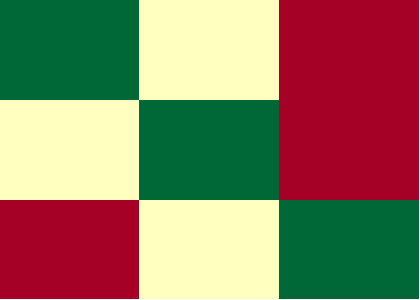

In [3]:
// --- Exemple guide 1 : resultat sincere et sensibilite au tiebreak ---
use ndarray::Array2;
use plotters::prelude::*;

const PROFILE: [[char; 3]; 3] = [
    ['A', 'B', 'C'],  // V1 : A en tete
    ['B', 'A', 'C'],  // V2 : B en tete
    ['C', 'B', 'A'],  // V3 : C en tete (peaks opposes a V1)
];

/// Position (0-based) d'un candidat dans un ordre ; -1 s'il est absent.
/// Remplace `liste.index(x)` de Python sans `unwrap` : la fonction est totale.
fn position_dans(candidat: char, ordre: [char; 3]) -> isize {
    for (i, &x) in ordre.iter().enumerate() {
        if x == candidat {
            return i as isize;
        }
    }
    -1
}

/// Pluralite : chaque electeur vote pour son rang 1. Tiebreak = ordre lexicographique.
fn plurality_winner(ballots: &[[char; 3]], tiebreak: [char; 3]) -> char {
    let mut scores = [0usize; 3];
    for b in ballots {
        scores[(b[0] as u8 - b'A') as usize] += 1;
    }
    // Cle composite de la source : score d'abord, puis position dans le tiebreak
    // (le plus tot gagne). La cle est unique : le maximum est bien determine.
    let cle = |c: char| -> (usize, isize) {
        (scores[(c as u8 - b'A') as usize], -position_dans(c, tiebreak))
    };
    let mut vainqueur = 'A';
    for &c in &['B', 'C'] {
        if cle(c) > cle(vainqueur) {
            vainqueur = c;
        }
    }
    vainqueur
}

/// Borda : 2 points au rang 1, 1 au rang 2, 0 au rang 3.
fn borda_winner(ballots: &[[char; 3]]) -> char {
    let mut scores = [0usize; 3];
    for b in ballots {
        for (r, &a) in b.iter().enumerate() {
            scores[(a as u8 - b'A') as usize] += 2 - r;
        }
    }
    // Cle de la source : score, puis ordre alphabetique (le plus petit gagne).
    let mut vainqueur = 'A';
    for &c in &['B', 'C'] {
        let kc = (scores[(c as u8 - b'A') as usize], -(c as i32));
        let kv = (scores[(vainqueur as u8 - b'A') as usize], -(vainqueur as i32));
        if kc > kv {
            vainqueur = c;
        }
    }
    vainqueur
}

/// Rang (1-based) d'une alternative dans une preference.
fn rank_of(alternative: char, preference: [char; 3]) -> usize {
    position_dans(alternative, preference) as usize + 1
}

// Pluralite sincere sous chaque tiebreak
println!("Pluralite sincere sous 3 tiebreaks :");
for tb in [['A', 'B', 'C'], ['B', 'A', 'C'], ['C', 'B', 'A']] {
    let w = plurality_winner(&PROFILE, tb);
    println!("  Tiebreak {}>{}>{} : vainqueur = {}", tb[0], tb[1], tb[2], w);
}

// Borda sincere
println!("\nBorda sincere : vainqueur = {} (deterministe, pas de tiebreak)", borda_winner(&PROFILE));

// Rang du vainqueur pour chaque votant
println!("\nRang du vainqueur A (tiebreak A) pour chaque votant :");
for (i, v_pref) in PROFILE.iter().enumerate() {
    println!("  V{} (pref {:?}) : rang de A = {}", i + 1, v_pref, rank_of('A', *v_pref));
}

// Matrice des rangs 3x3 : Array2<usize>, traduction de np.array cote Python.
let ranking = Array2::from_shape_fn((3, 3), |(i, j)| {
    rank_of(['A', 'B', 'C'][j], PROFILE[i])
});

// plotters est sans texte (feature ttf desactivee) : la grille des rangs est
// aussi imprimee en texte, pour que la lecture ne depende pas du rendu.
println!("\nGrille des rangs (1 = prefere, 3 = dernier) :");
println!("       A  B  C");
for i in 0..3 {
    println!("  V{}   {}  {}  {}", i + 1, ranking[[i, 0]], ranking[[i, 1]], ranking[[i, 2]]);
}

// Figure : grille 3x3 des rangs, couleurs RdYlGn_r (rang 1 vert, 2 jaune, 3 rouge).
// Le SVG est emis en image/svg+xml (jamais enrobe de HTML) pour le rendu GitHub.
let mut svg = String::new();
{
    let root = SVGBackend::with_string(&mut svg, (420, 300)).into_drawing_area();
    let mut chart = ChartBuilder::on(&root)
        .build_cartesian_2d(0.0f64..3.0, 3.0f64..0.0)?;
    chart
        .configure_mesh()
        .disable_x_mesh()
        .disable_y_mesh()
        .disable_axes()
        .draw()?;
    for i in 0..3 {
        for j in 0..3 {
            let couleur = match ranking[[i, j]] {
                1 => RGBColor(0x00, 0x68, 0x37),
                2 => RGBColor(0xFF, 0xFF, 0xBF),
                _ => RGBColor(0xA5, 0x00, 0x26),
            };
            chart.draw_series(std::iter::once(Rectangle::new(
                [(j as f64, i as f64), (j as f64 + 1.0, i as f64 + 1.0)],
                couleur.filled(),
            )))?;
        }
    }
    root.present()?;
}
println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);

println!("\nObservation : le vainqueur A est le pire choix pour V3 (rang 3).");
println!("C'est cette insatisfaction qui cree l'opportunite de manipulation.");

Depouillement : `A=1, B=1, C=1`. **Egalite triple**. Le tiebreak lexicographique designe A, comme le montre la sortie ci-dessus. Mais ce tiebreak est *arbitraire* : avec `B > A > C` le vainqueur est B (meilleur pour V2 et V3), avec `C > B > A` il est C (meilleur pour V3).

L'election sincere **depend du tiebreak**. C'est deja un defaut - une bonne regle devrait etre robuste aux details operationnels - mais ce n'est pas le seul. L'exemple guide 2 exhibe un temoin de manipulation sous le tiebreak `A > B > C` : un electeur peut, par un bulletin insincere, **changer le vainqueur vers un candidat qu'il prefere**.


### Exercice 1 : un profil a 4 votants ou le tiebreak decide

**Contexte.** L'exemple guide 1 montre que le vainqueur sincere de la Pluralite depend du tiebreak sur le profil a 3 votants. Reste a savoir si ce phenomene demande un profil particulier, et combien de votants il faut.

**Objectif.** Construire un profil de 4 votants (4 listes de preferences lineaires strictes sur `A`, `B`, `C`) tel que le vainqueur de la Pluralite change selon l'ordre de departage.

**Indices.**
- Le vainqueur de la Pluralite est le candidat le plus souvent classe premier. Le departage n'intervient que s'il y a une egalite au sommet.
- Deux candidats a egalite au premier rang suffisent pour que le tiebreak choisisse entre eux.
- En Rust, `profil_tiebreak` est un `Option<Vec<[char; 3]>>` : remplacer `None` par `Some(vec![...])`. La branche de verification parcourt la table `BALLOTS` (les six ordres de departage), trie les vainqueurs et les dedoublonne.

**Critere de verification.** La cellule suivante affiche l'ensemble des vainqueurs obtenus sur les six ordres de departage. Le profil est accepte si cet ensemble contient au moins deux candidats.


In [4]:
// --- Exercice 1 : un profil a 4 votants ou le tiebreak decide ---
/// Les six bulletins possibles, dans l'ordre lexicographique de
/// `itertools.permutations(['A', 'B', 'C'])` : l'ordre des lignes des tableaux
/// et le premier temoin trouve en dependent.
const BALLOTS: [[char; 3]; 6] = [
    ['A', 'B', 'C'],
    ['A', 'C', 'B'],
    ['B', 'A', 'C'],
    ['B', 'C', 'A'],
    ['C', 'A', 'B'],
    ['C', 'B', 'A'],
];

const PROFILE: [[char; 3]; 3] = [
    ['A', 'B', 'C'],  // V1 : A en tete
    ['B', 'A', 'C'],  // V2 : B en tete
    ['C', 'B', 'A'],  // V3 : C en tete (peaks opposes a V1)
];

/// Position (0-based) d'un candidat dans un ordre ; -1 s'il est absent.
/// Remplace `liste.index(x)` de Python sans `unwrap` : la fonction est totale.
fn position_dans(candidat: char, ordre: [char; 3]) -> isize {
    for (i, &x) in ordre.iter().enumerate() {
        if x == candidat {
            return i as isize;
        }
    }
    -1
}

/// Pluralite : chaque electeur vote pour son rang 1. Tiebreak = ordre lexicographique.
fn plurality_winner(ballots: &[[char; 3]], tiebreak: [char; 3]) -> char {
    let mut scores = [0usize; 3];
    for b in ballots {
        scores[(b[0] as u8 - b'A') as usize] += 1;
    }
    // Cle composite de la source : score d'abord, puis position dans le tiebreak
    // (le plus tot gagne). La cle est unique : le maximum est bien determine.
    let cle = |c: char| -> (usize, isize) {
        (scores[(c as u8 - b'A') as usize], -position_dans(c, tiebreak))
    };
    let mut vainqueur = 'A';
    for &c in &['B', 'C'] {
        if cle(c) > cle(vainqueur) {
            vainqueur = c;
        }
    }
    vainqueur
}

/// Borda : 2 points au rang 1, 1 au rang 2, 0 au rang 3.
fn borda_winner(ballots: &[[char; 3]]) -> char {
    let mut scores = [0usize; 3];
    for b in ballots {
        for (r, &a) in b.iter().enumerate() {
            scores[(a as u8 - b'A') as usize] += 2 - r;
        }
    }
    // Cle de la source : score, puis ordre alphabetique (le plus petit gagne).
    let mut vainqueur = 'A';
    for &c in &['B', 'C'] {
        let kc = (scores[(c as u8 - b'A') as usize], -(c as i32));
        let kv = (scores[(vainqueur as u8 - b'A') as usize], -(vainqueur as i32));
        if kc > kv {
            vainqueur = c;
        }
    }
    vainqueur
}

/// Rang (1-based) d'une alternative dans une preference.
fn rank_of(alternative: char, preference: [char; 3]) -> usize {
    position_dans(alternative, preference) as usize + 1
}

// TODO etudiant : remplacer None par un Vec de 4 preferences lineaires sur A, B, C
let profil_tiebreak: Option<Vec<[char; 3]>> = None; // TODO etudiant

if let Some(profil) = profil_tiebreak {
    let mut gagnants: Vec<char> = BALLOTS
        .iter()
        .map(|&tb| plurality_winner(&profil, tb))
        .collect();
    gagnants.sort();
    gagnants.dedup();
    println!("Vainqueurs possibles selon le tiebreak : {:?}", gagnants);
    if gagnants.len() > 1 {
        println!("Le tiebreak decide du vainqueur");
    } else {
        println!("Le vainqueur ne depend pas du tiebreak");
    }
} else {
    println!("Exercice a completer");
}
// evcxr : la cellule se termine sur une instruction, il n'affiche rien apres.
let _ = ();

Exercice a completer


## 3. Exemple guide 2 : Le temoin - exhiber un bulletin insincere gagnant

V3 prefere `C > B > A`. V1 vote A et V2 vote B : le bulletin de V3 est donc le seul levier. V3 cherche un bulletin `b'` qui fasse gagner un candidat qu'il prefere au vainqueur sincere.

Le code ci-dessous enumere les six bulletins possibles de V3, calcule le vainqueur de chacun et marque ceux qui ameliorent son rang.


### Question 2 : temoin de manipulation Pluralite


In [5]:
// --- Exemple guide 2 : trouver et exhiber le temoin de manipulation ---

// Strategie : pour V3, enumerer tous les bulletins possibles et chercher
// ceux qui produisent un resultat strictement meilleur que A.
const PROFILE: [[char; 3]; 3] = [
    ['A', 'B', 'C'],  // V1 : A en tete
    ['B', 'A', 'C'],  // V2 : B en tete
    ['C', 'B', 'A'],  // V3 : C en tete (peaks opposes a V1)
];

/// Position (0-based) d'un candidat dans un ordre ; -1 s'il est absent.
/// Remplace `liste.index(x)` de Python sans `unwrap` : la fonction est totale.
fn position_dans(candidat: char, ordre: [char; 3]) -> isize {
    for (i, &x) in ordre.iter().enumerate() {
        if x == candidat {
            return i as isize;
        }
    }
    -1
}

/// Pluralite : chaque electeur vote pour son rang 1. Tiebreak = ordre lexicographique.
fn plurality_winner(ballots: &[[char; 3]], tiebreak: [char; 3]) -> char {
    let mut scores = [0usize; 3];
    for b in ballots {
        scores[(b[0] as u8 - b'A') as usize] += 1;
    }
    // Cle composite de la source : score d'abord, puis position dans le tiebreak
    // (le plus tot gagne). La cle est unique : le maximum est bien determine.
    let cle = |c: char| -> (usize, isize) {
        (scores[(c as u8 - b'A') as usize], -position_dans(c, tiebreak))
    };
    let mut vainqueur = 'A';
    for &c in &['B', 'C'] {
        if cle(c) > cle(vainqueur) {
            vainqueur = c;
        }
    }
    vainqueur
}

/// Borda : 2 points au rang 1, 1 au rang 2, 0 au rang 3.
fn borda_winner(ballots: &[[char; 3]]) -> char {
    let mut scores = [0usize; 3];
    for b in ballots {
        for (r, &a) in b.iter().enumerate() {
            scores[(a as u8 - b'A') as usize] += 2 - r;
        }
    }
    // Cle de la source : score, puis ordre alphabetique (le plus petit gagne).
    let mut vainqueur = 'A';
    for &c in &['B', 'C'] {
        let kc = (scores[(c as u8 - b'A') as usize], -(c as i32));
        let kv = (scores[(vainqueur as u8 - b'A') as usize], -(vainqueur as i32));
        if kc > kv {
            vainqueur = c;
        }
    }
    vainqueur
}

/// Rang (1-based) d'une alternative dans une preference.
fn rank_of(alternative: char, preference: [char; 3]) -> usize {
    position_dans(alternative, preference) as usize + 1
}

/// Les six bulletins possibles, dans l'ordre lexicographique de
/// `itertools.permutations(['A', 'B', 'C'])` : l'ordre des lignes des tableaux
/// et le premier temoin trouve en dependent.
const BALLOTS: [[char; 3]; 6] = [
    ['A', 'B', 'C'],
    ['A', 'C', 'B'],
    ['B', 'A', 'C'],
    ['B', 'C', 'A'],
    ['C', 'A', 'B'],
    ['C', 'B', 'A'],
];

let voter = 2usize; // indice 0-based pour V3
let v_pref = PROFILE[voter];
let sincere_winner = plurality_winner(&PROFILE, ['A', 'B', 'C']);
let sincere_rank = rank_of(sincere_winner, v_pref);
println!("V{} preference sincere : {:?}", voter + 1, v_pref);
println!("Vainqueur sincere          : {}", sincere_winner);
println!("Rang de {} pour V{} : {}", sincere_winner, voter + 1, sincere_rank);
println!();

// Enumeration : tous les bulletins possibles de V3 (6 permutations)
println!("Recherche de bulletins insincres ameliorant le sort de V3 :");
println!();
println!("{:<25} {:<12} {:<12} {:<10}", "Bulletin V3", "Vainqueur", "Rang pour V3", "Gain");
println!("{}", "-".repeat(60));

let mut found_manipulation = false;
let mut manipulation_ballot = ['A', 'B', 'C'];
let mut manipulation_winner = 'A';
let mut manipulation_rank = 0usize;
for &insincere in BALLOTS.iter() {
    let mut ballots: Vec<[char; 3]> = PROFILE.to_vec();
    ballots[voter] = insincere;
    let w = plurality_winner(&ballots, ['A', 'B', 'C']);
    let new_rank = rank_of(w, v_pref);
    // Le gain peut etre negatif : soustraction en i32, jamais en usize.
    let gain = sincere_rank as i32 - new_rank as i32;
    let marker = if gain > 0 { "  <-- TEMOIN" } else { "" };
    println!(
        "  {:<23} {:<12} {:<12} {:<10}{}",
        format!("{:?}", insincere), w, new_rank, gain, marker
    );
    if gain > 0 && !found_manipulation {
        found_manipulation = true;
        manipulation_ballot = insincere;
        manipulation_winner = w;
        manipulation_rank = new_rank;
    }
}

println!();
if found_manipulation {
    println!("TEMOIN DE MANIPULATION (Pluralite) :");
    println!("  V{} sincere     : {:?}", voter + 1, v_pref);
    println!("  V{} manipule   : {:?}", voter + 1, manipulation_ballot);
    println!(
        "  Vainqueur sincere     : {} (rang {} pour V{})",
        sincere_winner, sincere_rank, voter + 1
    );
    println!(
        "  Vainqueur manipule    : {} (rang {} pour V{})",
        manipulation_winner, manipulation_rank, voter + 1
    );
    println!("  GAIN : rang {} -> rang {}", sincere_rank, manipulation_rank);
} else {
    println!("Aucune manipulation trouvee (erreur de profil).");
}
// evcxr : la cellule se termine sur une instruction, il n'affiche rien apres.
let _ = ();

V3 preference sincere : ['C', 'B', 'A']


Vainqueur sincere          : A


Rang de A pour V3 : 3


Recherche de bulletins insincres ameliorant le sort de V3 :


Bulletin V3               Vainqueur    Rang pour V3 Gain      


------------------------------------------------------------


... (8 outputs left out)

  V3 manipule   : ['B', 'A', 'C']


  Vainqueur sincere     : A (rang 3 pour V3)


  Vainqueur manipule    : B (rang 2 pour V3)


  GAIN : rang 3 -> rang 2


V3 vote `B > A > C` au lieu de `C > B > A`. Depouillement : A=1 (V1), B=2 (V2 et V3), C=0. **B gagne**. Le rang de B pour V3 est 2, alors que le vainqueur sincere A y est classe 3e. **Gain : rang 3 -> rang 2**. Le bulletin `B > C > A` produit le meme vainqueur et le meme gain, comme le montre la sortie.

C'est le temoin : un bulletin *concret* (`B > A > C` soumis par V3) + un *vainqueur* (B) + un *gain* (V3 passe de A a B dans son classement).


### Exercice 2 : le temoin a 4 votants

**Contexte.** L'exemple guide 2 cherche un bulletin insincere pour un seul votant (V3) sur un profil fixe. La definition du temoin ne depend ni du votant considere ni du nombre de votants : elle se generalise.

**Objectif.** Ecrire `temoin_plurality(profil, tiebreak)` qui parcourt tous les votants et tous leurs bulletins possibles. Elle renvoie le premier temoin trouve sous la forme `(indice du votant, bulletin insincere, vainqueur)`, ou `None` s'il n'en existe aucun.

**Indices.**
- Une boucle externe sur les votants, une boucle interne sur la table des six bulletins (`BALLOTS`, ordre lexicographique comme `itertools.permutations`), comme dans l'exemple guide 2.
- Le vainqueur sincere se calcule une seule fois avec `plurality_winner(&profil, tiebreak)`.
- Le rang de ce vainqueur dans la preference du votant se lit avec `rank_of`.

**Critere de verification.** Sur le profil de l'exemple guide 2, la fonction doit retrouver le temoin de cet exemple (V3, bulletin `B > A > C`). Sur `PROFIL_4`, elle doit renvoyer un temoin, que la cellule affiche.


In [6]:
// --- Exercice 2 : le temoin a 4 votants ---
const PROFILE: [[char; 3]; 3] = [
    ['A', 'B', 'C'],  // V1 : A en tete
    ['B', 'A', 'C'],  // V2 : B en tete
    ['C', 'B', 'A'],  // V3 : C en tete (peaks opposes a V1)
];

/// Position (0-based) d'un candidat dans un ordre ; -1 s'il est absent.
/// Remplace `liste.index(x)` de Python sans `unwrap` : la fonction est totale.
fn position_dans(candidat: char, ordre: [char; 3]) -> isize {
    for (i, &x) in ordre.iter().enumerate() {
        if x == candidat {
            return i as isize;
        }
    }
    -1
}

/// Pluralite : chaque electeur vote pour son rang 1. Tiebreak = ordre lexicographique.
fn plurality_winner(ballots: &[[char; 3]], tiebreak: [char; 3]) -> char {
    let mut scores = [0usize; 3];
    for b in ballots {
        scores[(b[0] as u8 - b'A') as usize] += 1;
    }
    // Cle composite de la source : score d'abord, puis position dans le tiebreak
    // (le plus tot gagne). La cle est unique : le maximum est bien determine.
    let cle = |c: char| -> (usize, isize) {
        (scores[(c as u8 - b'A') as usize], -position_dans(c, tiebreak))
    };
    let mut vainqueur = 'A';
    for &c in &['B', 'C'] {
        if cle(c) > cle(vainqueur) {
            vainqueur = c;
        }
    }
    vainqueur
}

/// Borda : 2 points au rang 1, 1 au rang 2, 0 au rang 3.
fn borda_winner(ballots: &[[char; 3]]) -> char {
    let mut scores = [0usize; 3];
    for b in ballots {
        for (r, &a) in b.iter().enumerate() {
            scores[(a as u8 - b'A') as usize] += 2 - r;
        }
    }
    // Cle de la source : score, puis ordre alphabetique (le plus petit gagne).
    let mut vainqueur = 'A';
    for &c in &['B', 'C'] {
        let kc = (scores[(c as u8 - b'A') as usize], -(c as i32));
        let kv = (scores[(vainqueur as u8 - b'A') as usize], -(vainqueur as i32));
        if kc > kv {
            vainqueur = c;
        }
    }
    vainqueur
}

/// Rang (1-based) d'une alternative dans une preference.
fn rank_of(alternative: char, preference: [char; 3]) -> usize {
    position_dans(alternative, preference) as usize + 1
}

/// Renvoie (indice du votant, bulletin insincere, vainqueur) d'un temoin, ou None.
fn temoin_plurality(_profil: &[[char; 3]], _tiebreak: [char; 3]) -> Option<(usize, [char; 3], char)> {
    // TODO etudiant : parcourir tous les votants, puis leurs 6 bulletins possibles
    None // TODO etudiant
}

const PROFIL_4: [[char; 3]; 4] = [
    ['A', 'B', 'C'], // V1
    ['B', 'A', 'C'], // V2
    ['B', 'A', 'C'], // V3
    ['C', 'A', 'B'], // V4
];

let temoin = temoin_plurality(&PROFIL_4, ['A', 'B', 'C']);
if let Some((votant, bulletin, gagnant)) = temoin {
    println!(
        "Controle sur le profil de l'exemple guide 2 : {:?}",
        temoin_plurality(&PROFILE, ['A', 'B', 'C'])
    );
    println!("Temoin : V{} vote {:?} -> vainqueur {}", votant + 1, bulletin, gagnant);
} else {
    println!("Exercice a completer");
}
// evcxr : la cellule se termine sur une instruction, il n'affiche rien apres.
let _ = ();

Exercice a completer


## 4. Exemple guide 3 : Comparer les regles - Pluralite vs Borda

La manipulation existe-t-elle aussi sous **Borda** sur le meme profil ? Si oui, est-elle plus ou moins difficile a trouver ?

**Hypothese** : Borda prend en compte l'ordre complet, pas seulement le rang 1. Un electeur qui manipule en Borda doit *anticiper* comment son bulletin modifie le score relatif de plusieurs candidats. La manipulation est possible mais demande plus de calcul.

L'exemple **mesure** l'effort de recherche : combien de tentatives un electeur doit-il faire avant de trouver une manipulation ?


### Question 3 : la meme manipulation existe-t-elle sous Borda ?


In [7]:
// --- Exemple guide 3 : Borda est-elle egalement manipulable sur ce profil ? ---
use plotters::prelude::*;

const PROFILE: [[char; 3]; 3] = [
    ['A', 'B', 'C'],  // V1 : A en tete
    ['B', 'A', 'C'],  // V2 : B en tete
    ['C', 'B', 'A'],  // V3 : C en tete (peaks opposes a V1)
];

/// Position (0-based) d'un candidat dans un ordre ; -1 s'il est absent.
/// Remplace `liste.index(x)` de Python sans `unwrap` : la fonction est totale.
fn position_dans(candidat: char, ordre: [char; 3]) -> isize {
    for (i, &x) in ordre.iter().enumerate() {
        if x == candidat {
            return i as isize;
        }
    }
    -1
}

/// Pluralite : chaque electeur vote pour son rang 1. Tiebreak = ordre lexicographique.
fn plurality_winner(ballots: &[[char; 3]], tiebreak: [char; 3]) -> char {
    let mut scores = [0usize; 3];
    for b in ballots {
        scores[(b[0] as u8 - b'A') as usize] += 1;
    }
    // Cle composite de la source : score d'abord, puis position dans le tiebreak
    // (le plus tot gagne). La cle est unique : le maximum est bien determine.
    let cle = |c: char| -> (usize, isize) {
        (scores[(c as u8 - b'A') as usize], -position_dans(c, tiebreak))
    };
    let mut vainqueur = 'A';
    for &c in &['B', 'C'] {
        if cle(c) > cle(vainqueur) {
            vainqueur = c;
        }
    }
    vainqueur
}

/// Borda : 2 points au rang 1, 1 au rang 2, 0 au rang 3.
fn borda_winner(ballots: &[[char; 3]]) -> char {
    let mut scores = [0usize; 3];
    for b in ballots {
        for (r, &a) in b.iter().enumerate() {
            scores[(a as u8 - b'A') as usize] += 2 - r;
        }
    }
    // Cle de la source : score, puis ordre alphabetique (le plus petit gagne).
    let mut vainqueur = 'A';
    for &c in &['B', 'C'] {
        let kc = (scores[(c as u8 - b'A') as usize], -(c as i32));
        let kv = (scores[(vainqueur as u8 - b'A') as usize], -(vainqueur as i32));
        if kc > kv {
            vainqueur = c;
        }
    }
    vainqueur
}

/// Rang (1-based) d'une alternative dans une preference.
fn rank_of(alternative: char, preference: [char; 3]) -> usize {
    position_dans(alternative, preference) as usize + 1
}

/// Les six bulletins possibles, dans l'ordre lexicographique de
/// `itertools.permutations(['A', 'B', 'C'])` : l'ordre des lignes des tableaux
/// et le premier temoin trouve en dependent.
const BALLOTS: [[char; 3]; 6] = [
    ['A', 'B', 'C'],
    ['A', 'C', 'B'],
    ['B', 'A', 'C'],
    ['B', 'C', 'A'],
    ['C', 'A', 'B'],
    ['C', 'B', 'A'],
];

let voter = 2usize;
let v_pref = PROFILE[voter];
let sincere_borda_winner = borda_winner(&PROFILE);
let sincere_borda_rank = rank_of(sincere_borda_winner, v_pref);
println!(
    "Vainqueur Borda sincere : {} (rang {} pour V{})",
    sincere_borda_winner, sincere_borda_rank, voter + 1
);
println!();

// Enumeration exhaustive des bulletins de V3
println!("{:<25} {:<18} {:<10} {:<8}", "Bulletin V3", "Vainqueur Borda", "Rang V3", "Gain");
println!("{}", "-".repeat(65));
let mut borda_manipulations: Vec<([char; 3], char, usize)> = Vec::new();
for &insincere in BALLOTS.iter() {
    let mut ballots: Vec<[char; 3]> = PROFILE.to_vec();
    ballots[voter] = insincere;
    let w = borda_winner(&ballots);
    let new_rank = rank_of(w, v_pref);
    let gain = sincere_borda_rank as i32 - new_rank as i32;
    let marker = if gain > 0 { "  <-- TEMOIN" } else { "" };
    println!(
        "  {:<23} {:<18} {:<10} {:<8}{}",
        format!("{:?}", insincere), w, new_rank, gain, marker
    );
    if gain > 0 {
        borda_manipulations.push((insincere, w, new_rank));
    }
}

println!();
if borda_manipulations.is_empty() {
    println!("Borda : AUCUN temoin de manipulation pour V3 sur ce profil.");
    println!("Les scores Borda sinceres sont :");
    let mut scores_sinceres = [0usize; 3];
    for b in &PROFILE {
        for (r, &a) in b.iter().enumerate() {
            scores_sinceres[(a as u8 - b'A') as usize] += 2 - r;
        }
    }
    // Tri stable par score decroissant (l'ordre A, B, C de la source en cas d'egalite).
    let mut classement: Vec<(char, usize)> = vec![
        ('A', scores_sinceres[0]),
        ('B', scores_sinceres[1]),
        ('C', scores_sinceres[2]),
    ];
    classement.sort_by_key(|&(_, score)| std::cmp::Reverse(score));
    for (alt, score) in &classement {
        println!("  {} = {} points", alt, score);
    }
    // Conclusion derivee (PAS de chaine en dur)
    let (top1, s1) = classement[0];
    let (top2, s2) = classement[1];
    let marge = s1 - s2;
    let pts = if marge == 1 { "point" } else { "points" };
    println!("  -> {} devance {} de {} {} ({} vs {}).", top1, top2, marge, pts, s1, s2);
} else {
    println!("Borda : {} temoin(s) de manipulation trouve(s).", borda_manipulations.len());
    for (ins, w, r) in &borda_manipulations {
        println!("  V3 vote {:?} -> {} (rang {} pour V3)", ins, w, r);
    }
}

// La comparaison synthetique recalcule la manipulabilite de la Pluralite : cette
// cellule est autonome, `found_manipulation` de l'exemple guide 2 n'existe pas ici.
let sincere_plurality_winner = plurality_winner(&PROFILE, ['A', 'B', 'C']);
let sincere_plurality_rank = rank_of(sincere_plurality_winner, v_pref);
let mut bulletin_manipule = ['B', 'A', 'C'];
let mut pluralite_manipulable = false;
for &insincere in BALLOTS.iter() {
    let mut ballots: Vec<[char; 3]> = PROFILE.to_vec();
    ballots[voter] = insincere;
    let w = plurality_winner(&ballots, ['A', 'B', 'C']);
    if rank_of(w, v_pref) < sincere_plurality_rank && !pluralite_manipulable {
        pluralite_manipulable = true;
        bulletin_manipule = insincere;
    }
}

println!();
println!("=== Comparaison synthetique ===");
println!(
    "Pluralite : {} (exploitation du tiebreak)",
    if pluralite_manipulable { "MANIPULABLE" } else { "NON MANIPULABLE" }
);
println!(
    "Borda     : {} (sur ce profil precis)",
    if borda_manipulations.is_empty() { "NON MANIPULABLE" } else { "MANIPULABLE" }
);
println!();
println!("Conclusion nuancee : Pluralite est PLUS facile a manipuler ici, mais Borda");
println!("est structurellement manipulable aussi (Gibbard-Satterthwaite) - le profil");
println!("didactique choisi ici protege Borda par les marges importantes des scores.");
println!("Sur un profil ou les marges sont plus serrees, Borda admet aussi des temoins.");

// Figures (titres et legendes en texte : plotters est sans texte).
println!();
println!("Figure gauche : voix Pluralite, sincere contre manipule (V3 vote B > A > C).");
println!("Figure droite : points Borda sinceres ; ligne rouge = score du vainqueur B.");

fn voix_pluralite(ballots: &[[char; 3]]) -> [usize; 3] {
    let mut voix = [0usize; 3];
    for b in ballots {
        voix[(b[0] as u8 - b'A') as usize] += 1;
    }
    voix
}

let sincere_p = voix_pluralite(&PROFILE);
let mut ballots_manipules: Vec<[char; 3]> = PROFILE.to_vec();
ballots_manipules[voter] = bulletin_manipule;
let manip_p = voix_pluralite(&ballots_manipules);

let mut scores_plot = [0usize; 3];
for b in &PROFILE {
    for (r, &a) in b.iter().enumerate() {
        scores_plot[(a as u8 - b'A') as usize] += 2 - r;
    }
}
let mut ranked: Vec<(char, usize)> = vec![
    ('A', scores_plot[0]),
    ('B', scores_plot[1]),
    ('C', scores_plot[2]),
];
ranked.sort_by_key(|&(_, score)| std::cmp::Reverse(score));
let (w_alt, w_sc) = ranked[0];

let mut svg = String::new();
{
    let root = SVGBackend::with_string(&mut svg, (880, 340)).into_drawing_area();
    let areas = root.split_evenly((1, 2));

    // Panneau 1 : voix Pluralite, sincere (bleu clair) contre manipule (corail).
    {
        let mut chart1 = ChartBuilder::on(&areas[0])
            .build_cartesian_2d(-0.5f64..2.5, 0.0f64..2.5)?;
        chart1
            .configure_mesh()
            .disable_x_mesh()
            .disable_y_mesh()
            .disable_axes()
            .draw()?;
        for i in 0..3 {
            let x = i as f64;
            chart1.draw_series(std::iter::once(Rectangle::new(
                [(x - 0.35, 0.0), (x - 0.05, sincere_p[i] as f64)],
                RGBColor(0xAD, 0xD8, 0xE6).filled(),
            )))?;
            chart1.draw_series(std::iter::once(Rectangle::new(
                [(x + 0.05, 0.0), (x + 0.35, manip_p[i] as f64)],
                RGBColor(0xF0, 0x80, 0x80).filled(),
            )))?;
        }
        root.present()?;
    }

    // Panneau 2 : points Borda sinceres (vert clair), ligne du vainqueur en rouge.
    {
        let mut chart2 = ChartBuilder::on(&areas[1])
            .build_cartesian_2d(-0.5f64..2.5, 0.0f64..5.5)?;
        chart2
            .configure_mesh()
            .disable_x_mesh()
            .disable_y_mesh()
            .disable_axes()
            .draw()?;
        for i in 0..3 {
            let x = i as f64;
            chart2.draw_series(std::iter::once(Rectangle::new(
                [(x - 0.3, 0.0), (x + 0.3, scores_plot[i] as f64)],
                RGBColor(0x90, 0xEE, 0x90).filled(),
            )))?;
        }
        // Ligne horizontale au score du vainqueur, en tirets (petits rectangles).
        let y = w_sc as f64;
        let mut x = -0.45f64;
        while x < 2.5 {
            chart2.draw_series(std::iter::once(Rectangle::new(
                [(x, y - 0.04), (x + 0.12, y + 0.04)],
                RED.filled(),
            )))?;
            x += 0.24;
        }
        root.present()?;
    }
}
println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);
println!("Scores Borda du panneau droit : {} = {} points (vainqueur).", w_alt, w_sc);

Vainqueur Borda sincere : B (rang 2 pour V3)


Bulletin V3               Vainqueur Borda    Rang V3    Gain    


-----------------------------------------------------------------


  ['A', 'B', 'C']         A                  3          -1      


  ['A', 'C', 'B']         A                  3          -1      


  ['B', 'A', 'C']         B                  2          0       


... (15 outputs left out)

Sur un profil ou les marges sont plus serrees, Borda admet aussi des temoins.


Figure gauche : voix Pluralite, sincere contre manipule (V3 vote B > A > C).


Figure droite : points Borda sinceres ; ligne rouge = score du vainqueur B.


Scores Borda du panneau droit : B = 4 points (vainqueur).


Sur ce profil, Borda n'est pas manipulable par V3 : aucun bulletin ne fait gagner un candidat que V3 prefere a B, qui a 4 points contre 3 pour A et 2 pour C (scores imprimes par la cellule ci-dessus). La comparaison donne donc, pour V3, Pluralite manipulable et Borda non manipulable sur ce profil precis. Attention au perimetre : ce balayage ne teste que V3 - sur ce MEME profil, V1 peut manipuler Borda (en declarant A>C>B au lieu de A>B>C, les scores deviennent A=3, B=3, C=3 et le departage alphabetique elit A au lieu de B, ce qui ameliore le rang de A pour V1 de 2 a 1). La fragilite du tiebreak rend Pluralite facilement manipulable ici. Pourquoi V3 est-il protege sous Borda sur ce profil ? Avant meme le bulletin de V3, les bulletins fixes de V1 et V2 distribuent 6 points : A=3, B=3, C=0. Quel que soit le bulletin de V3, C (son prefere) plafonne a 2 points tandis que A ou B atteint au moins 4 : C ne gagne jamais, et les six bulletins de V3 font gagner A ou B - jamais un resultat meilleur pour lui que B au sincere (rang 2). Borda reste structurellement manipulable (V1 ci-dessus, ou d'autres profils). L'exercice 3 cherche un profil a 3 votants ou Borda l'est.


### Exercice 3 : un profil a 3 votants ou Borda est manipulable

**Contexte.** L'exemple guide 3 ne trouve aucun temoin de Borda sur son profil. Le theoreme de Gibbard-Satterthwaite dit qu'il existe des profils ou une regle non dictatoriale sur 3 alternatives est manipulable : reste a exhiber un tel profil pour Borda, avec 3 votants.

**Objectif.** Parmi les profils a 3 votants sur `A`, `B`, `C`, trouver un profil, un votant et un bulletin insincere tels que le votant obtienne, avec ce bulletin, un vainqueur Borda strictement meilleur pour lui.

**Indices.**
- Les six bulletins possibles sont listes dans l'enonce de la fonction (`ABC, ACB, BAC, BCA, CAB, CBA`) ; une triple boucle imbriquee enumere les profils a 3 votants (l'equivalent de `itertools.product`).
- `rank_of` donne le rang d'un candidat dans une preference, et `borda_winner` le vainqueur d'un ensemble de bulletins.
- Le departage de `borda_winner` est alphabetique. Un profil dont le vainqueur apres manipulation est unique evite de dependre de ce departage.

**Critere de verification.** La cellule suivante affiche le profil trouve et deux booleens. Le profil est accepte si les deux valent `true`.


In [8]:
// --- Exercice 3 : chercher un profil a 3 votants ou Borda est manipulable ---

/// Renvoie (profil, indice du votant, bulletin insincere) ou None.
fn cherche_profil_borda_manipulable() -> Option<(Vec<[char; 3]>, usize, [char; 3])> {
    // TODO etudiant : enumerer les profils (triple boucle sur les six bulletins
    // ABC, ACB, BAC, BCA, CAB, CBA), puis les votants et leurs bulletins
    None // TODO etudiant
}

/// Scores Borda : 2 points au rang 1, 1 au rang 2, 0 au rang 3.
fn scores_borda(bulletins: &[[char; 3]]) -> [usize; 3] {
    let mut scores = [0usize; 3];
    for b in bulletins {
        for (r, &a) in b.iter().enumerate() {
            scores[(a as u8 - b'A') as usize] += 2 - r;
        }
    }
    scores
}

/// Position (0-based) d'un candidat dans un ordre ; -1 s'il est absent.
fn position_dans(candidat: char, ordre: [char; 3]) -> isize {
    for (i, &x) in ordre.iter().enumerate() {
        if x == candidat {
            return i as isize;
        }
    }
    -1
}

/// Borda : 2 points au rang 1, 1 au rang 2, 0 au rang 3 (meme regle que l'exemple guide 3).
fn borda_winner(ballots: &[[char; 3]]) -> char {
    let mut scores = [0usize; 3];
    for b in ballots {
        for (r, &a) in b.iter().enumerate() {
            scores[(a as u8 - b'A') as usize] += 2 - r;
        }
    }
    let mut vainqueur = 'A';
    for &c in &['B', 'C'] {
        let kc = (scores[(c as u8 - b'A') as usize], -(c as i32));
        let kv = (scores[(vainqueur as u8 - b'A') as usize], -(vainqueur as i32));
        if kc > kv {
            vainqueur = c;
        }
    }
    vainqueur
}

/// Rang (1-based) d'une alternative dans une preference.
fn rank_of(alternative: char, preference: [char; 3]) -> usize {
    position_dans(alternative, preference) as usize + 1
}

let resultat = cherche_profil_borda_manipulable();
if let Some((profil, votant, bulletin)) = resultat {
    let mut apres: Vec<[char; 3]> = profil.clone();
    apres[votant] = bulletin;
    let s = scores_borda(&apres);
    let ameliore = rank_of(borda_winner(&apres), profil[votant])
        < rank_of(borda_winner(&profil), profil[votant]);
    let mut max_score = 0usize;
    for &x in &s {
        if x > max_score {
            max_score = x;
        }
    }
    let unique = s.iter().filter(|&&x| x == max_score).count() == 1;
    println!("Profil : {:?}", profil);
    println!(
        "V{} vote {:?} : amelioration = {}, vainqueur unique apres manipulation = {}",
        votant + 1, bulletin, ameliore, unique
    );
} else {
    println!("Exercice a completer");
}
// evcxr : la cellule se termine sur une instruction, il n'affiche rien apres.
let _ = ();

Exercice a completer


## 5. Conclusion : ce que le temoin prouve

**Trois resultats a retenir** :

1. **Le temoin est constructif** - sur le profil canonique de Satterthwaite, un electeur (V3) peut exhiber un bulletin *concret* (`B > A > C` au lieu de `C > B > A`) qui ameliore son sort sous Pluralite (rang 3 -> rang 2). La preuve d'exploitation n'est pas abstraite : c'est un objet qu'on tient en main.

2. **La regle de vote n'est pas une propriete abstraite** - Pluralite se manipule par exploitation du tiebreak (1 voix suffit), Borda se manipule en fabriquant un vainqueur prefere : ici V3 ne le peut pas parce que C plafonne a 2 points quand A ou B atteint au moins 4 (arithmetique de la section 4) - l'ecart sincere B=4 vs A=3 n'est que le symptome de cette impossibilite. Le choix d'une regle est un choix sur les **chemins de manipulation** qu'on rend possibles.

3. **Gibbard-Satterthwaite est structurel** - pour *toute* regle surjective et non dictatoriale avec >=3 alternatives, il *existe* un profil manipulable : le theoreme ne dit pas que tout profil l'est : le profil choisi ici ne fait qu'*exhiber* un temoin pour Pluralite, et le theoreme dit qu'on en trouverait un pour Borda aussi sur un profil approprie. C'est la portee universelle du resultat.

**Limites du modele** : ce profil est minimal (3 electeurs, 3 alternatives). La litterature etend le resultat a N electeurs et M alternatives, avec des bornes sur le nombre de manipulations selon la structure de la regle (e.g. regles a seuil, regles a veto, regles positionnelles). La complexite de la recherche de manipulation est elle-meme un objet d'etude : certaines regles sont *strategyproof* sur des domaines restreints (e.g. preferences unimodales pour la regle du vote majoritaire a 2 tours), mais pas sur le domaine general.

**Lien avec la science politique** : la manipulation par bulletin insincere est observee empiriquement dans les elections reelles. Le resultat theorique explique pourquoi : il serait etonnant que les electeurs *ne* trouvent pas de manipulation, puisque le theoreme garantit qu'il en existe. Les parades institutionnelles (bulletin secret, depouillement public, education civique) reduisent l'incitation sans elever la barriere computationnelle - c'est la these de Riker (1982) sur l'heresthetic.
## References bibliographiques

- Gibbard, A. (1973). Manipulation of Voting Schemes: A General Result. Econometrica 41(4):587-601.
- Satterthwaite, M.A. (1975). Strategy-proofness and Arrow's Conditions: Existence and Correspondence Theorems for Voting Procedures and Social Welfare Functions. Journal of Economic Theory 10(2):187-217.
- Brandt, F., Conitzer, V., Endriss, U., Lang, J., Procaccia, A. D. (2016). *Handbook of Computational Social Choice*. Cambridge University Press. ISBN 978-1-107-06043-2. **Ancrage ch. 6, §6.2 « Gibbard-Satterthwaite and Its Implications » (Conitzer et Walsh)** - la barriere calculatoire a la manipulation comme angle d'attaque des resultats d'impossibilite : ou la complexite de trouver une manipulation profitable protege en pratique la procedure. Source biblio cluster : `G:\Mon Drive\MyIA\IA\Bibliographie IA\GameTheory\Social Choice, Voting and Welfare\2016 - Brandt Conitzer Endriss Lang - Handbook of Computational Social Choice.pdf`.


## À retenir

| Leçon | Mesure dans ce carnet |
|---|---|
| Un seul profil, trois vainqueurs : c'est le tiebreak qui décide | `Tiebreak A>B>C : vainqueur = A`, `Tiebreak B>A>C : vainqueur = B`, `Tiebreak C>B>A : vainqueur = C` |
| Deux règles usuelles divergent sur ce même profil | `Vainqueur Pluralite sincere : A` contre `Vainqueur Borda sincere     : B` (`-> Pluralite A, Borda B : divergent.`) |
| La fragilité de la règle se lit dans le rang du gagnant | `Rang de A pour V3 : 3 (dernier)` — le vainqueur de la pluralité est le **pire** choix de V3 |
| Le témoin de manipulation est un objet, pas une intuition | `V3 manipule : ['B', 'A', 'C']` puis `Vainqueur manipule : B (rang 2 pour V3)` et `GAIN : rang 3 -> rang 2` |
| L'impossibilité pour un votant se démontre par l'arithmétique des scores | Avant le bulletin de V3, A et B ont déjà 3 points chacun et C plafonne à 2 : `Borda : AUCUN temoin de manipulation pour V3 sur ce profil` — l'écart sincère `B = 4 points` contre `A = 3 points` n'en est que le symptôme |
| L'absence de témoin pour UN votant n'est pas une immunité | `Pluralite : MANIPULABLE (exploitation du tiebreak)` et `Borda     : NON MANIPULABLE (sur ce profil precis)` ; V1, lui, manipule Borda sur ce même profil (voir section 4) |


## Vérifiez votre compréhension

**Question 1 — Sur le profil de ce carnet, V3 peut-il améliorer son rang sous Borda ?**

La section 4 affiche le tableau des six bulletins possibles pour V3, avec des gains de `-1` ou `0`, puis la ligne `Borda : AUCUN temoin de manipulation pour V3 sur ce profil`.

<details><summary>Réponse</summary>

Non pour V3, sur **ce** profil (mais oui pour V1 : voir le contre-exemple de la section 4). Les six bulletins possibles de V3 sont tous évalués, et aucun ne fait gagner à V3 un candidat qu'il préfère à B : les gains sont `-1` ou `0`, jamais positif. La raison est donnée par les scores : `B = 4 points`, `A = 3 points`, `C = 2 points`, donc `B devance A de 1 point`. La marge initiale n'est que le symptôme : la vraie raison est arithmétique — avant le bulletin de V3, A et B ont déjà 3 points chacun et C plafonne à 2, donc C ne peut jamais gagner (section 4). Ce que ce résultat ne dit pas : que Borda est strategyproof. Le carnet le dit lui-même — `Pluralite : MANIPULABLE (exploitation du tiebreak)`, `Borda : NON MANIPULABLE par V3 (sur ce profil precis)` — et l'exercice 3 demande justement le profil où Borda cesse d'être protégé. Et le carnet montre aussi que la protection ne vaut que pour V3 : V1 améliore son rang sous Borda sur ce même profil (section 4).

</details>

**Question 2 — Pourquoi la fragilité attribuée ici à la règle porte-t-elle sur le tiebreak plutôt que sur la règle elle-même ?**

La section 2 affiche trois vainqueurs pour un seul profil : `Tiebreak A>B>C : vainqueur = A`, `Tiebreak B>A>C : vainqueur = B`, `Tiebreak C>B>A : vainqueur = C`, tandis que la même section affiche `Borda sincere : vainqueur = B (deterministe, pas de tiebreak)`.

<details><summary>Réponse</summary>

Parce qu'au **sincère**, le vainqueur tient tout entier à l'**ordre arbitraire des égalités** : trois ordres de départage différents donnent trois vainqueurs différents sur un profil inchangé — rien dans les préférences ne décide, c'est la convention qui décide. Le témoin, lui, combine deux leviers : le bulletin insincère modifie le dépouillement (B passe à 2 voix contre 1 et gagne **sans égalité**), et c'est le départage qui avait élu A au sincère. La fragilité du départage est ce qui rend le gain accessible ici, pas le seul mécanisme du gain. Borda, sur le même profil, n'a pas besoin de cette convention et rend un vainqueur unique, déterministe. Sur CE profil, la pluralité offre un témoin immédiat quand Borda n'en offre aucun pour V3 — sans que cela mesure une difficulté générale de manipulation. Le mécanisme du témoin est d'ailleurs explicite : `V3 manipule : ['B', 'A', 'C']` retire une voix à C pour la donner à B, qui gagne alors seul (2 voix contre 1) — sans départage cette fois — et fait passer V3 du rang 3 au rang 2.

</details>


## Pour aller plus loin

- [Index de la sous-série SocialChoice](README.md) — le fil de la sous-série et ce que chaque carnet y ajoute.
- [Index de la série GameTheory](../README.md) — la place de l'impossibilité de manipulation parmi les autres structures de la théorie des jeux.

Les carnets voisins sont cités en prose, sans lien. `ChoixSocial-01-Arrow-Impossibility-Theorem-Python` pose le cadre axiomatique qui précède celui-ci : l'impossibilité de manipulation y est l'aboutissement d'une famille de conditions, alors que ce carnet en montre le mécanisme sur un profil unique. `ChoixSocial-06-Mobius-Aggregation-Pouvoir-Manipulation-Python` attaque le même objet par l'agrégation de Möbius et le pouvoir de manipulation, et `ChoixSocial-10-Manipulation-Strategique-MultiWinner-Python` le mesure sur un espace exhaustif de 216 profils, avec les règles à comité. `ChoixSocial-09-Committees-STV-Monroe-ChamberlinCourant-Python` complète le tableau avec les règles de sélection à plusieurs sièges.

La suite du travail est déjà posée dans le carnet : l'exercice 3 demande le profil à trois votants sur lequel Borda admet un témoin, et l'exercice 1 le profil à quatre votants où c'est le tiebreak seul qui décide du vainqueur.
